<a href="https://colab.research.google.com/github/linus-ireri/ML-Projects/blob/main/Week_6_Assignment_%7C_Discovering_Patterns_in_Data_Clustering_Analysis_for_VeritasRAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Assignment: Clustering Analysis for VeritasRAG

## 1. Objective

The objective of this assignment is to apply unsupervised machine learning to group questions according to their textual characteristics. This investigation supports the VeritasRAG university information chatbot, which aims to help students find relevant university information.

I will use the Stanford Question Answering Dataset (SQuAD), which contains questions, text passages, and answers. I will focus on the question text and investigate whether K-Means clustering can identify groups of questions with similar vocabulary and content.

## 2. Selected Features

The primary feature will be the **question text**. I will convert the text into numerical TF-IDF features, which represent the importance of words in each question relative to the dataset.

I will also calculate question length and word count to help describe the resulting clusters.

The clustering model will use the TF-IDF representations because K-Means requires numerical input. The question length and word count will be used to interpret the groups rather than as the main clustering inputs.

In [2]:
!pip -q install datasets scikit-learn pandas matplotlib seaborn

from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the SQuAD training dataset using its correct full hub name
dataset = load_dataset("rajpurkar/squad", split="train[:3000]")

# Create a DataFrame
df = pd.DataFrame({
    "question": dataset["question"],
    "context": dataset["context"],
    "answer": [a["text"][0] if a["text"] else ""
               for a in dataset["answers"]]
})

# Remove missing or duplicate questions
df = df.dropna(subset=["question"])
df = df.drop_duplicates(subset=["question"]).reset_index(drop=True)

# Calculate descriptive features
df["word_count"] = df["question"].str.split().str.len()
df["character_count"] = df["question"].str.len()

# Perform TF-IDF Vectorization on the question text to create X and vectorizer
vectorizer = TfidfVectorizer(max_features=1000, stop_words="english")
X = vectorizer.fit_transform(df["question"])

print("Dataset shape:", df.shape)
print("TF-IDF matrix shape:", X.shape)
display(df.head())

README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

Dataset shape: (2988, 5)
TF-IDF matrix shape: (2988, 1000)


,question,context,answer,word_count,character_count
0,To whom did the Virgin Mary allegedly appear i...,"Architecturally, the school has a Catholic cha...",Saint Bernadette Soubirous,13,71
1,What is in front of the Notre Dame Main Building?,"Architecturally, the school has a Catholic cha...",a copper statue of Christ,10,49
2,The Basilica of the Sacred heart at Notre Dame...,"Architecturally, the school has a Catholic cha...",the Main Building,14,76
3,What is the Grotto at Notre Dame?,"Architecturally, the school has a Catholic cha...",a Marian place of prayer and reflection,7,33
4,What sits on top of the Main Building at Notre...,"Architecturally, the school has a Catholic cha...",a golden statue of the Virgin Mary,11,52


In [3]:
# This cell was a duplicate of the data loading step.
# We have updated the main data loading cell above with the necessary TF-IDF transformations.
print("Data preparation and TF-IDF extraction are now fully handled in the previous cell.")

Data preparation and TF-IDF extraction are now fully handled in the previous cell.


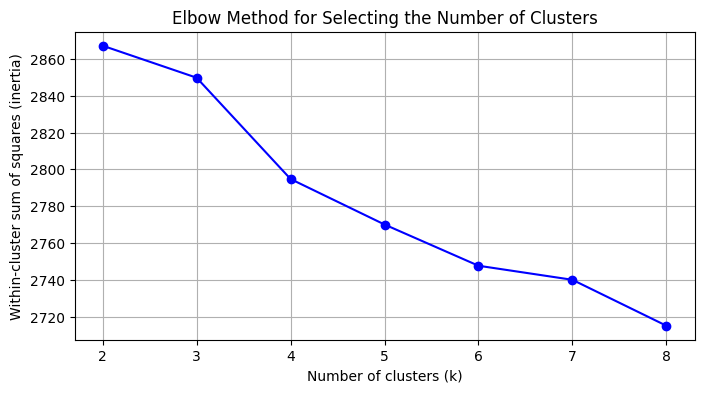

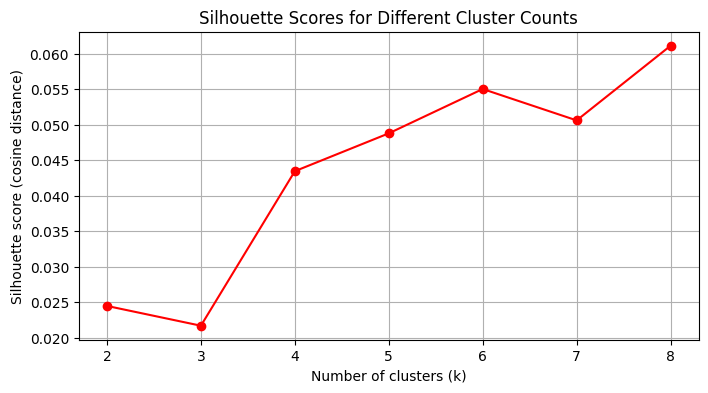

,Number of clusters,Inertia,Silhouette score
0,2,2867.1841,0.0245
1,3,2849.7852,0.0217
2,4,2794.7426,0.0435
3,5,2770.0220,0.0488
4,6,2747.6218,0.0550
5,7,2739.9805,0.0506
6,8,2715.0229,0.0611


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    # Calculate cosine silhouette score on a sample of the data for efficiency
    silhouette_scores.append(silhouette_score(
        X, labels, metric="cosine", sample_size=min(1000, X.shape[0]),
        random_state=42
    ))

# Plot elbow curve
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertias, marker="o", color="b")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (inertia)")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Compare silhouette scores
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), silhouette_scores, marker="o", color="r")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score (cosine distance)")
plt.title("Silhouette Scores for Different Cluster Counts")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

results = pd.DataFrame({
    "Number of clusters": list(k_values),
    "Inertia": inertias,
    "Silhouette score": silhouette_scores
})
display(results.round(4))

Questions assigned to each cluster:


,Question count
cluster,
0,1996
1,217
2,307
3,468


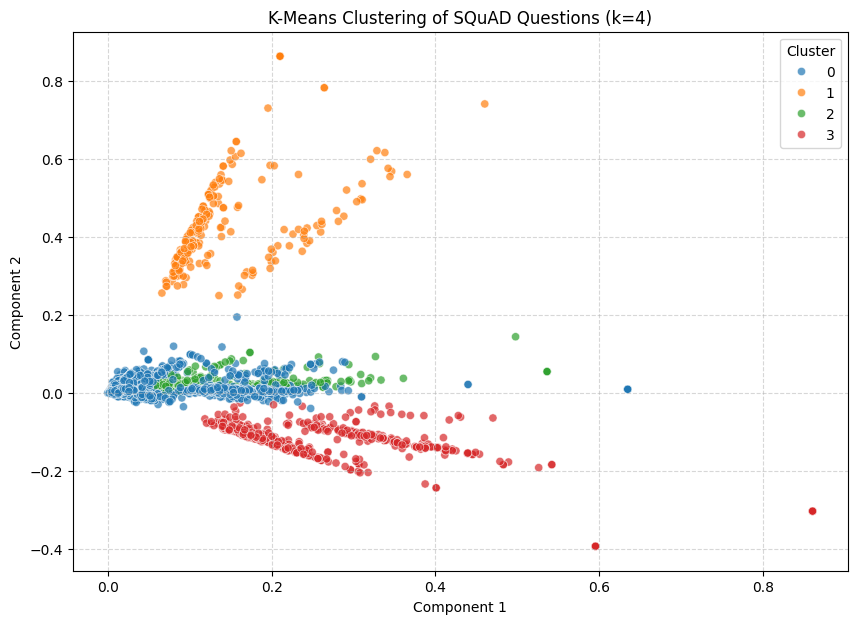

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

# Fit the final clustering model
k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X)

print("Questions assigned to each cluster:")
display(df["cluster"].value_counts().sort_index().rename("Question count"))

# Reduce the TF-IDF vectors to 2 dimensions for visualization
svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X)

plot_df = pd.DataFrame({
    "Component 1": X_2d[:, 0],
    "Component 2": X_2d[:, 1],
    "Cluster": df["cluster"].astype(str)
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="Component 1",
    y="Component 2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=35
)
plt.title("K-Means Clustering of SQuAD Questions (k=4)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [6]:
import pandas as pd
import numpy as np

# Identify the most important terms in each cluster using the centroid weights
terms = vectorizer.get_feature_names_out()
centroids = kmeans.cluster_centers_

for cluster_id in range(k):
    top_indices = centroids[cluster_id].argsort()[-10:][::-1]
    top_terms = [terms[i] for i in top_indices]

    print(f"\nCLUSTER {cluster_id}")
    print("Important terms:", ", ".join(top_terms))

    print("\nSample questions:")
    samples = df.loc[df["cluster"] == cluster_id, "question"].head(5)
    for question in samples:
        print("-", question)

# Compare cluster sizes and average question lengths
cluster_summary = df.groupby("cluster").agg(
    number_of_questions=("question", "size"),
    average_word_count=("word_count", "mean"),
    average_character_count=("character_count", "mean")
).round(2)

display(cluster_summary)


CLUSTER 0
Important terms: did, beyoncé, ipod, does, frédéric, year, antibiotics, apple, montana, genocide

Sample questions:
- To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
- Where is the headquarters of the Congregation of the Holy Cross?
- What is the primary seminary of the Congregation of the Holy Cross?
- Which prize did Frederick Buechner create?
- How many departments are within the Stinson-Remick Hall of Engineering?

CLUSTER 1
Important terms: notre, dame, year, president, students, did, college, library, football, student

Sample questions:
- What is in front of the Notre Dame Main Building?
- The Basilica of the Sacred heart at Notre Dame is beside to which structure?
- What is the Grotto at Notre Dame?
- What sits on top of the Main Building at Notre Dame?
- When did the Scholastic Magazine of Notre dame begin publishing?

CLUSTER 2
Important terms: beyonce, did, album, year, movie, song, called, film, music, artist

Sample questions:
- When did 

,number_of_questions,average_word_count,average_character_count
cluster,,,
0,1996,10.26,59.59
1,217,12.14,68.00
2,307,9.91,57.89
3,468,9.95,58.01


# Discussion and Conclusion

## Discussion

K-Means clustering was applied to TF-IDF representations of questions from the SQuAD dataset. The number of clusters was investigated using the elbow method and silhouette scores. The final model grouped questions according to similarities in their textual features.

The two-dimensional visualization provides an overview of the distribution of the clusters. Points assigned to the same cluster may share vocabulary or question patterns, while overlapping regions suggest that some questions have similar characteristics across different groups.

The most important terms and sample questions from each cluster can help explain what the groups represent. For example, groups may contain questions about people, locations, dates, events, or other factual topics. The actual interpretation should be based on the terms and questions produced by the model.

## Relevance to VeritasRAG

This experiment demonstrates how unsupervised machine learning can discover patterns in questions without requiring predefined categories. In VeritasRAG, a similar approach could help explore student enquiries and identify recurring topics such as admissions, fees, academic programmes, and university services.

However, clustering questions is different from retrieving authoritative answers. The results of this experiment would be exploratory and would not, by themselves, establish that the chatbot provides accurate answers.

## Conclusion

The experiment demonstrates the use of TF-IDF feature extraction, K-Means clustering, cluster-count comparison, and visualization to investigate text data. It also shows how unsupervised learning can support exploratory analysis of questions relevant to an information retrieval chatbot.